# SEM.9.7 — Notebook 4: The bed — specific gauge and altimetric low water (methods)

Reproducibility notebook for **SFFS technical report SEM.9.7, *Geomorphic Evolution of the Lower Semliki: Bed and Bank Change, 2000–2026*** (Ministry of Water and Environment, Uganda, 2026), Sections 4.4, 4.5 and 8.

**The data for this part are not distributed with this package.** The discharge gaugings at Bweramule (DWRM station 85205, 1950–2025) are held by the Ministry of Water and Environment, Uganda, and are available from the Ministry on request. Altimetric water levels at the virtual stations are distributed by Hydroweb (Theia / CNES, https://hydroweb.next.theia-land.fr) under its own terms and can be downloaded there free of charge.

This notebook therefore documents the method and the input formats, and runs it on a **synthetic, clearly labelled example** so that the code can be checked. Replace the example files with the real ones to reproduce Section 8 of the report.

**Input formats**

* `gaugings.csv`: `date` (YYYY-MM-DD), `stage_m` (on one gauge datum), `Q_m3s`, optional `area_m2`.
* `altimetry/<station>.csv`: `date`, `height_m`; and `altimetry/stations.csv`: `id`, `lon`, `lat`.

In [1]:
import os, csv, datetime as dt
import numpy as np
import matplotlib.pyplot as plt
rng = np.random.default_rng(7)
GAUGINGS = None          # path to a real gaugings.csv; None runs the synthetic example
ALTIMETRY_DIR = None     # folder with real Hydroweb series; None runs the synthetic example

## 1  Specific gauge

For each epoch, stage is regressed on ln Q and the stage for 150, 200 and 250 m³/s is read from the fit wherever that flow lies inside the epoch's gauged range (±5 %). A bed that aggrades raises the stage for a fixed flow; scour or widening lowers it.

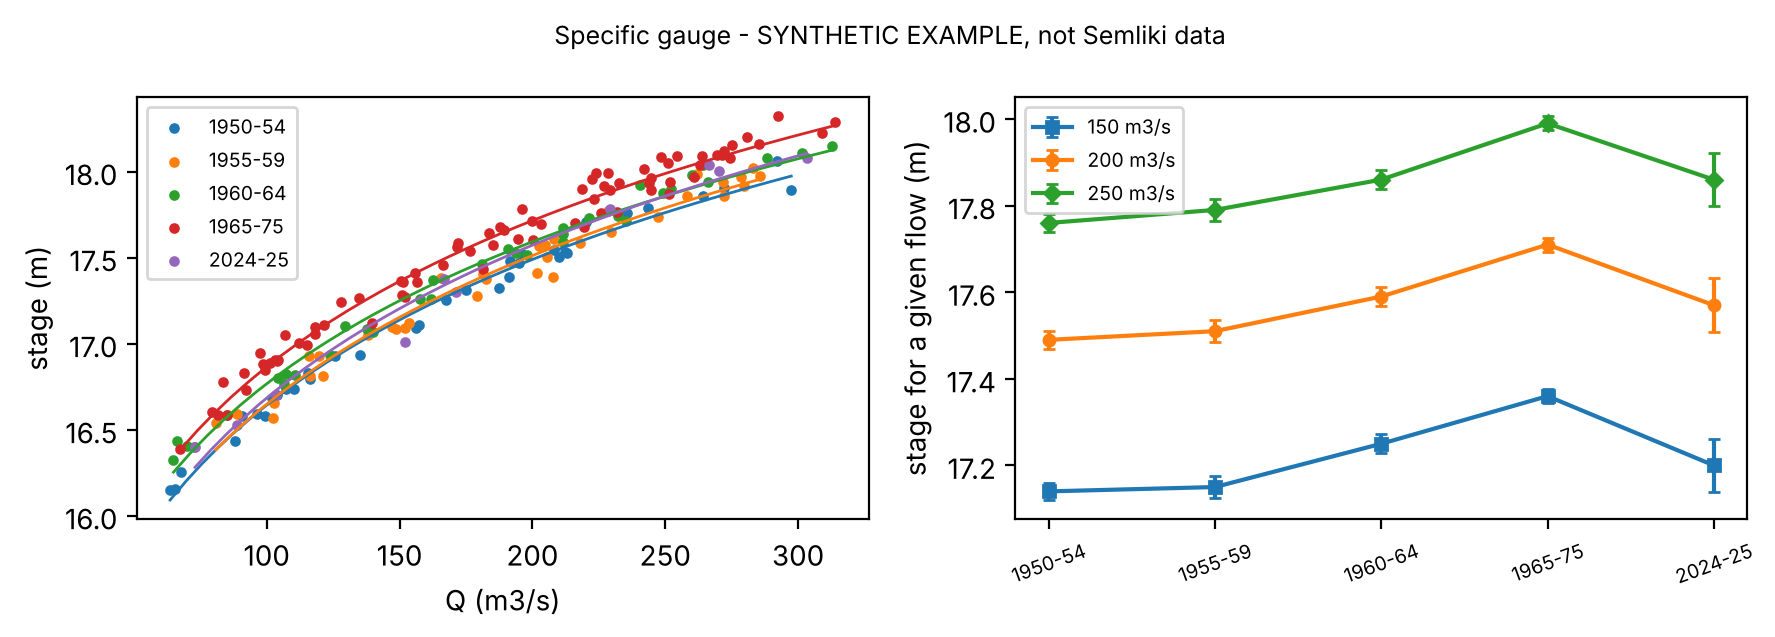

{'epoch': '1950-54', 'n': 35, 'se_m': 0.01, 'h150': 17.14, 'h200': 17.49, 'h250': 17.76}
{'epoch': '1955-59', 'n': 35, 'se_m': 0.013, 'h150': 17.15, 'h200': 17.51, 'h250': 17.79}
{'epoch': '1960-64', 'n': 35, 'se_m': 0.011, 'h150': 17.25, 'h200': 17.59, 'h250': 17.86}
{'epoch': '1965-75', 'n': 77, 'se_m': 0.008, 'h150': 17.36, 'h200': 17.71, 'h250': 17.99}
{'epoch': '2024-25', 'n': 10, 'se_m': 0.031, 'h150': 17.2, 'h200': 17.57, 'h250': 17.86}


In [2]:
def synthetic_gaugings():
    # ILLUSTRATIVE ONLY: a power-law rating whose control rises 0.3 m between 1955 and 1975, with 5 % gauging error
    rows = []
    for y in list(range(1950, 1976)) + [2024, 2025]:
        shift = 0.0 if y < 1955 else (0.3 * min(1, (y - 1955) / 20) if y < 2000 else 0.05)
        for _ in range(7 if y < 2000 else 5):
            Q = float(rng.uniform(60, 300)); h = 14.0 + shift + (Q / 9.0) ** (1 / 2.5) * 1.0
            rows.append({"date": "%d-06-15" % y, "stage_m": h, "Q_m3s": Q * float(np.exp(rng.normal(0, .05)))})
    return rows

G = list(csv.DictReader(open(GAUGINGS))) if GAUGINGS else synthetic_gaugings()
EPOCHS = [("1950-54", 1950, 1954), ("1955-59", 1955, 1959), ("1960-64", 1960, 1964), ("1965-75", 1965, 1975), ("2024-25", 2024, 2025)]
spec = []
fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
for lab, a, b in EPOCHS:
    pts = [(float(r["stage_m"]), float(r["Q_m3s"])) for r in G if a <= int(str(r["date"])[:4]) <= b]
    if len(pts) < 4:
        continue
    h = np.array([p[0] for p in pts]); q = np.array([p[1] for p in pts])
    c = np.polyfit(np.log(q), h, 1); res = h - np.polyval(c, np.log(q)); se = res.std(ddof=2) / np.sqrt(len(h))
    row = {"epoch": lab, "n": len(h), "se_m": round(float(se), 3)}
    for Q in (150, 200, 250):
        row["h%d" % Q] = round(float(np.polyval(c, np.log(Q))), 2) if q.min() * .95 <= Q <= q.max() * 1.05 else None
    spec.append(row)
    ax[0].scatter(q, h, s=8, label=lab); qq = np.linspace(q.min(), q.max(), 40); ax[0].plot(qq, np.polyval(c, np.log(qq)), lw=1)
for Q, mk in ((150, "s"), (200, "o"), (250, "D")):
    xs = [i for i, r in enumerate(spec) if r["h%d" % Q] is not None]
    ax[1].errorbar(xs, [spec[i]["h%d" % Q] for i in xs], yerr=[2 * spec[i]["se_m"] for i in xs], fmt=mk + "-", ms=4, capsize=2, label="%d m3/s" % Q)
ax[1].set_xticks(range(len(spec))); ax[1].set_xticklabels([r["epoch"] for r in spec], rotation=20, fontsize=7)
ax[0].set_xlabel("Q (m3/s)"); ax[0].set_ylabel("stage (m)"); ax[0].legend(fontsize=7); ax[1].legend(fontsize=7); ax[1].set_ylabel("stage for a given flow (m)")
fig.suptitle("Specific gauge" + ("" if GAUGINGS else " - SYNTHETIC EXAMPLE, not Semliki data"), fontsize=9); fig.tight_layout(); plt.show()
for r in spec: print(r)

## 2  Altimetric low water

For each virtual station with at least six measurements in at least four years, the annual 10th percentile of the water level is the low-water level, and its trend is the Theil–Sen slope. Stations are placed on the reach by their nearest baseline point. Mission biases of up to ±0.3 m mean altimetric trends indicate rather than measure bed change.

In [3]:
def theil_sen(x, y):
    return float(np.median([(y[j] - y[i]) / (x[j] - x[i]) for i in range(len(x)) for j in range(i + 1, len(x)) if x[j] != x[i]]))

def annual_low(series):
    by = {}
    for d, h in series:
        by.setdefault(int(str(d)[:4]), []).append(float(h))
    lows = {y: np.percentile(v, 10) for y, v in by.items() if len(v) >= 6}
    yy = np.array(sorted(lows)); return yy, np.array([lows[y] for y in yy])

if ALTIMETRY_DIR:
    st = list(csv.DictReader(open(os.path.join(ALTIMETRY_DIR, "stations.csv"))))
    data = {s["id"]: [(r["date"], r["height_m"]) for r in csv.DictReader(open(os.path.join(ALTIMETRY_DIR, s["id"] + ".csv")))] for s in st}
else:   # ILLUSTRATIVE ONLY: three stations, one with a rising low water, two flat
    data = {}
    for sid, trend in (("example_A", 0.13), ("example_B", 0.02), ("example_C", 0.0)):
        data[sid] = [("%d-%02d-15" % (y, m), 600 + trend * (y - 2008) + 0.6 * np.sin(m / 12 * 2 * np.pi) + rng.normal(0, .15))
                     for y in range(2008, 2027) for m in range(1, 13, 1) if rng.random() < .8]
for sid, s in data.items():
    yy, ll = annual_low(s)
    if len(yy) >= 4:
        print("%-12s %d-%d  low-water trend %+.3f m/yr" % (sid, yy[0], yy[-1], theil_sen(yy, ll)))

example_A    2008-2026  low-water trend +0.134 m/yr
example_B    2008-2026  low-water trend +0.016 m/yr
example_C    2008-2026  low-water trend +0.005 m/yr
